<a href="https://colab.research.google.com/github/AryamEzra/Event-SNN-Baseline/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cell 1: Install

In [1]:
!pip install -q snntorch tonic

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.8/109.8 kB 5.8 MB/s eta 0:00:00


# Cell 2: Imports and config

In [2]:
import os, json, time, random, shutil
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import snntorch as snn
from snntorch import surrogate
import snntorch.functional as SF
import tonic, tonic.transforms as transforms
import matplotlib.pyplot as plt

SEED, T, BATCH, EPOCHS, LR = 42, 25, 128, 10, 2e-3
QUICK = False   # set True first for a 2-minute smoke test on a small subset

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True)
print("Device:", device)

Device: cuda


# Cell 3: Data (N-MNIST event dataset)

In [3]:
sensor_size = tonic.datasets.NMNIST.sensor_size  # (34, 34, 2)
tf_snn = transforms.ToFrame(sensor_size=sensor_size, n_time_bins=T)  # T time-binned frames
tf_cnn = transforms.ToFrame(sensor_size=sensor_size, n_time_bins=1)  # all events -> 1 frame

def make_loaders(tf, tag):
    tr = tonic.datasets.NMNIST(save_to="./data", train=True, transform=tf)
    te = tonic.datasets.NMNIST(save_to="./data", train=False, transform=tf)
    tr = tonic.DiskCachedDataset(tr, cache_path=f"./cache/{tag}_train")
    te = tonic.DiskCachedDataset(te, cache_path=f"./cache/{tag}_test")
    if QUICK:
        rng = np.random.RandomState(SEED)
        tr = Subset(tr, rng.choice(len(tr), 5000, replace=False).tolist())
        te = Subset(te, rng.choice(len(te), 1000, replace=False).tolist())
    return (DataLoader(tr, batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True),
            DataLoader(te, batch_size=BATCH, num_workers=2))

snn_train, snn_test = make_loaders(tf_snn, "snn")
cnn_train, cnn_test = make_loaders(tf_cnn, "cnn")
x, y = next(iter(snn_train)); print("SNN batch:", x.shape)   # [B, T, 2, 34, 34]
x, y = next(iter(cnn_train)); print("CNN batch:", x.shape)   # [B, 1, 2, 34, 34]

  0%|          | 0/1011893601 [00:00<?, ?it/s]

Extracting ./data/NMNIST/train.zip to ./data/NMNIST


  0%|          | 0/169674850 [00:00<?, ?it/s]

Extracting ./data/NMNIST/test.zip to ./data/NMNIST
SNN batch: torch.Size([128, 25, 2, 34, 34])
CNN batch: torch.Size([128, 1, 2, 34, 34])


# Cell 4: Models

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(2, 12, 5)
        self.conv2 = nn.Conv2d(12, 32, 5)
        self.fc = nn.Linear(32 * 5 * 5, 10)
    def forward(self, x):                       # x: [B, 2, 34, 34]
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc(x.flatten(1))

class SNN(nn.Module):
    def __init__(self, beta=0.9):
        super().__init__()
        sg = surrogate.fast_sigmoid(slope=25)
        self.conv1 = nn.Conv2d(2, 12, 5);  self.lif1 = snn.Leaky(beta=beta, spike_grad=sg)
        self.conv2 = nn.Conv2d(12, 32, 5); self.lif2 = snn.Leaky(beta=beta, spike_grad=sg)
        self.fc = nn.Linear(32 * 5 * 5, 10); self.lif3 = snn.Leaky(beta=beta, spike_grad=sg)
    def forward(self, x):                       # x: [T, B, 2, 34, 34]
        m1, m2, m3 = self.lif1.init_leaky(), self.lif2.init_leaky(), self.lif3.init_leaky()
        out, cnt = [], torch.zeros(4, device=x.device)
        for t in range(x.size(0)):
            xt = x[t]
            s1, m1 = self.lif1(F.max_pool2d(self.conv1(xt), 2), m1)
            s2, m2 = self.lif2(F.max_pool2d(self.conv2(s1), 2), m2)
            s3, m3 = self.lif3(self.fc(s2.flatten(1)), m3)
            out.append(s3)
            cnt += torch.stack([xt.sum(), s1.sum(), s2.sum(), s3.sum()]).detach()
        return torch.stack(out), cnt            # spikes [T,B,10], spike counts [in,s1,s2,s3]

# Cell 5: Train and evaluate

In [5]:
def prep_snn(x): return x.float().clamp(max=1).permute(1, 0, 2, 3, 4).to(device)  # -> [T,B,...]
def prep_cnn(x): return torch.log1p(x.float().squeeze(1)).to(device)               # -> [B,2,34,34]

def run_cnn(epochs=EPOCHS):
    model, hist = CNN().to(device), []
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for ep in range(epochs):
        model.train()
        for x, y in cnn_train:
            loss = F.cross_entropy(model(prep_cnn(x)), y.to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval(); c = n = 0
        with torch.no_grad():
            for x, y in cnn_test:
                c += (model(prep_cnn(x)).argmax(1).cpu() == y).sum().item(); n += len(y)
        hist.append(c / n); print(f"[CNN] epoch {ep+1}/{epochs}  test acc {c/n:.4f}")
    return model, hist

def run_snn(epochs=EPOCHS):
    model, hist = SNN().to(device), []
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = SF.ce_rate_loss()
    for ep in range(epochs):
        model.train()
        for x, y in snn_train:
            spk, _ = model(prep_snn(x))
            loss = loss_fn(spk, y.to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval(); c = n = 0; cnt = torch.zeros(4, device=device)
        with torch.no_grad():
            for x, y in snn_test:
                spk, k = model(prep_snn(x)); cnt += k
                c += (spk.sum(0).argmax(1).cpu() == y).sum().item(); n += len(y)
        hist.append(c / n); print(f"[SNN] epoch {ep+1}/{epochs}  test acc {c/n:.4f}")
    return model, hist, (cnt / n).cpu().numpy()   # avg spike counts per sample (over all T)

t0 = time.time(); cnn_model, cnn_hist = run_cnn();  print("CNN time:", round(time.time()-t0), "s")
t0 = time.time(); snn_model, snn_hist, spk_counts = run_snn(); print("SNN time:", round(time.time()-t0), "s")

[CNN] epoch 1/10  test acc 0.9546
[CNN] epoch 2/10  test acc 0.9633
[CNN] epoch 3/10  test acc 0.9699
[CNN] epoch 4/10  test acc 0.9670
[CNN] epoch 5/10  test acc 0.9726
[CNN] epoch 6/10  test acc 0.9710
[CNN] epoch 7/10  test acc 0.9746
[CNN] epoch 8/10  test acc 0.9702
[CNN] epoch 9/10  test acc 0.9740
[CNN] epoch 10/10  test acc 0.9724
CNN time: 716 s
[SNN] epoch 1/10  test acc 0.9409
[SNN] epoch 2/10  test acc 0.9593
[SNN] epoch 3/10  test acc 0.9689
[SNN] epoch 4/10  test acc 0.9759
[SNN] epoch 5/10  test acc 0.9790
[SNN] epoch 6/10  test acc 0.9740
[SNN] epoch 7/10  test acc 0.9768
[SNN] epoch 8/10  test acc 0.9812
[SNN] epoch 9/10  test acc 0.9779
[SNN] epoch 10/10  test acc 0.9815
SNN time: 1517 s


# Cell 6: Sparsity and operation/energy analysis

In [6]:
# Neurons per time step: input 2*34*34, layer1 12*15*15, layer2 32*5*5, output 10
neurons = np.array([2*34*34, 12*15*15, 32*5*5, 10])
fanout  = np.array([12*5*5, 32*5*5, 10])   # synapses triggered per input spike (conv1, conv2, fc), ignores borders

firing_rate = spk_counts / (neurons * T)                       # avg spikes/neuron/timestep
synops = float((spk_counts[:3] * fanout).sum())                # SNN synaptic ops per sample
macs_cnn = 30*30*12*(2*5*5) + 11*11*32*(12*5*5) + 800*10       # CNN MACs per sample
macs_snn_dense = macs_cnn * T                                  # SNN if every synapse fired every step

# Energy ASSUMPTIONS (estimates, not measurements)
E_MAC, E_AC = 4.6e-12, 0.9e-12      # ~45nm 32-bit float MAC / add (Horowitz, ISSCC 2014 -- verify before citing)
E_LOIHI_SYNOP = 23.6e-12            # min energy per synaptic spike op, Loihi pre-silicon, 14nm (Davies et al. 2018, Table 2)

res = {
    "cnn_acc": cnn_hist[-1], "snn_acc": snn_hist[-1],
    "firing_rate_per_layer": dict(zip(["input", "layer1", "layer2", "output"], firing_rate.tolist())),
    "cnn_macs": macs_cnn, "snn_synops": synops, "snn_dense_equiv_macs": macs_snn_dense,
    "cnn_energy_uJ": macs_cnn * E_MAC * 1e6,
    "snn_energy_uJ_generic_AC": synops * E_AC * 1e6,
    "snn_energy_uJ_loihi_synop": synops * E_LOIHI_SYNOP * 1e6,
    "cnn_hist": cnn_hist, "snn_hist": snn_hist, "T": T, "epochs": EPOCHS,
}
json.dump(res, open("results/results.json", "w"), indent=2)
for k, v in res.items():
    if "hist" not in k: print(f"{k}: {v}")

cnn_acc: 0.9724
snn_acc: 0.9815
firing_rate_per_layer: {'input': 0.043951411791738754, 'layer1': 0.10824422743055556, 'layer2': 0.347619677734375, 'output': 0.10989559936523438}
cnn_macs: 1709600
snn_synops: 6676829.697265625
snn_dense_equiv_macs: 42740000
cnn_energy_uJ: 7.864159999999999
snn_energy_uJ_generic_AC: 6.009146727539062
snn_energy_uJ_loihi_synop: 157.57318085546873
T: 25
epochs: 10


# Cell 7: Plots for the paper

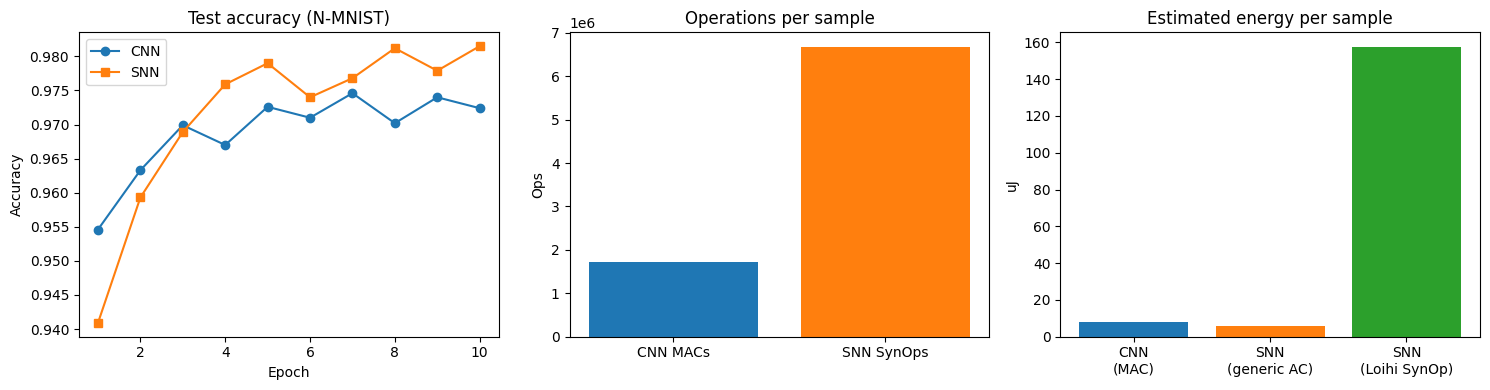

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ep = range(1, EPOCHS + 1)
ax[0].plot(ep, cnn_hist, "o-", label="CNN"); ax[0].plot(ep, snn_hist, "s-", label="SNN")
ax[0].set(title="Test accuracy (N-MNIST)", xlabel="Epoch", ylabel="Accuracy"); ax[0].legend()

ax[1].bar(["CNN MACs", "SNN SynOps"], [macs_cnn, synops], color=["tab:blue", "tab:orange"])
ax[1].set(title="Operations per sample", ylabel="Ops")

ax[2].bar(["CNN\n(MAC)", "SNN\n(generic AC)", "SNN\n(Loihi SynOp)"],
          [res["cnn_energy_uJ"], res["snn_energy_uJ_generic_AC"], res["snn_energy_uJ_loihi_synop"]],
          color=["tab:blue", "tab:orange", "tab:green"])
ax[2].set(title="Estimated energy per sample", ylabel="uJ")
plt.tight_layout(); plt.savefig("results/summary.png", dpi=200); plt.show()

# Cell 8: Download everything

In [9]:
shutil.make_archive("results_bundle", "zip", "results")
try:
    from google.colab import files; files.download("results_bundle.zip")
except Exception:
    print("On Kaggle: the zip is in the Output tab (right sidebar).")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>